# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Nabella Putri Kumalla
- **Email:** nabellaputri93@gmail.com
- **ID Dicoding:** nabella_putri28

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memperoleh informasi yang mendalam.

* **Spesific (Spesifik):** Pertanyaan harus jelas dan fokus pada topik tertentu
* **Measurable (Terukur):** Pertanyaan harus bisa dijawab dengan angka yang konkret
* **Action-Oriented (Berorientasi Aksi):** Hasil pertanyaan harus bisa memberikan arahan tindakan nyata
* **Relevant (Relevan):** Hasil pertanyaan harus sejalan dengan tujuan utama bisnis
* **Time-bound (Terikat Waktu):** Pertanyaan harus memiliki batasan waktu yang jelas

- **Pertanyaan 1:** Bagaimana pola penggunaan sepeda per jam dalam sehari berdasarkan tipe pengguna (kasual vs terdaftar) pada hari kerja dan akhir pekan selama periode 2011–2012, dan pada jam berapa saja terjadi puncak peminjaman?

  - **Specific:** Fokus pada pola per jam berdasarkan tipe pengguna dan jenis hari
  - **Measurable:** Diukur dengan rata-rata jumlah peminjaman per jam
  - **Action-Oriented:** Hasilnya dapat digunakan untuk optimasi distribusi sepeda
  - **Relevant:** Relevan untuk meningkatkan efisiensi layanan bike sharing
  - **Time-bound:** Dibatasi pada periode 2011–2012

- **Pertanyaan 2:** Faktor lingkungan apa (musim, kondisi cuaca, suhu) yang paling signifikan memengaruhi jumlah total peminjaman sepeda harian selama periode 2011–2012, dan bagaimana rekomendasinya untuk optimasi layanan?

  - **Specific:** Fokus pada faktor lingkungan (musim, cuaca, suhu) terhadap peminjaman harian
  - **Measurable:** Diukur dengan rata-rata peminjaman harian dan koefisien korelasi
  - **Action-Oriented:** Hasilnya dapat digunakan untuk strategi operasional musiman
  - **Relevant:** Relevan untuk perencanaan armada dan promosi layanan
  - **Time-bound:** Dibatasi pada periode 2011–2012

## Import Semua Packages/Library yang Digunakan

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120

print('Library berhasil diimport!')

Library berhasil diimport!


## Data Wrangling

### Gathering Data

Pada tahap ini, kita mengumpulkan dan memuat semua data yang dibutuhkan ke dalam format DataFrame. Dataset Bike Sharing terdiri dari dua file:
- `data/day.csv` — data agregat harian (731 baris)
- `data/hour.csv` — data per jam (17.379 baris)

#### Load day.csv

In [ ]:
day_df = pd.read_csv('data/day.csv')
print(f'Ukuran dataset day.csv: {day_df.shape}')
day_df.head()

Ukuran dataset day.csv: (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


#### Load hour.csv

In [ ]:
hour_df = pd.read_csv('data/hour.csv')
print(f'Ukuran dataset hour.csv: {hour_df.shape}')
hour_df.head()

Ukuran dataset hour.csv: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- Dataset `day.csv` memiliki 731 baris (731 hari = 2 tahun) dan 16 kolom
- Dataset `hour.csv` memiliki 17.379 baris dan 17 kolom (tambahan kolom `hr` untuk jam)
- Kolom `cnt` adalah total peminjaman = `casual` + `registered`
- Nilai `temp` dan `atemp` sudah dinormalisasi ke rentang [0,1]
- Kolom kategori masih berupa kode numerik, perlu dipetakan ke label yang lebih mudah dibaca

### Assessing Data

Pada tahap ini kita menilai kualitas data dengan mengidentifikasi masalah yang mungkin ada.

#### Identifying Missing Values

In [ ]:
print('=== Missing Values - day_df ===')
print(day_df.isnull().sum())
print(f'\nTotal missing values: {day_df.isnull().sum().sum()}')

print('\n=== Missing Values - hour_df ===')
print(hour_df.isnull().sum())
print(f'\nTotal missing values: {hour_df.isnull().sum().sum()}')

=== Missing Values - day_df ===
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Total missing values: 0

=== Missing Values - hour_df ===
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Total missing values: 0


#### Identifying Duplicate Data

In [ ]:
print(f'Duplikat di day_df: {day_df.duplicated().sum()}')
print(f'Duplikat di hour_df: {hour_df.duplicated().sum()}')

Duplikat di day_df: 0
Duplikat di hour_df: 0


#### Identifying Inaccurate Data Types

In [ ]:
print('=== Tipe Data day_df ===')
print(day_df.dtypes)
print('\n=== Info Statistik day_df ===')
day_df.describe()

=== Tipe Data day_df ===
instant         int64
dteday         object
season          int64
yr              int64
mnth            int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object

=== Info Statistik day_df ===


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


#### Identifying Inconsistent Values (Kolom Kategorik)

In [ ]:
cat_cols = ['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit']
for col in cat_cols:
    print(f'{col}: {sorted(day_df[col].unique())}')

season: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
yr: [np.int64(0), np.int64(1)]
mnth: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
holiday: [np.int64(0), np.int64(1)]
weekday: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
workingday: [np.int64(0), np.int64(1)]
weathersit: [np.int64(1), np.int64(2), np.int64(3)]


**Steps to Take:**
- Kolom `dteday` perlu dikonversi dari `object` (string) ke tipe `datetime`
- Kolom-kolom kategori (`season`, `weathersit`, `weekday`, `mnth`, `yr`) perlu dipetakan ke label yang lebih deskriptif
- Nilai `temp` dan `atemp` perlu didenormalisasi: `temp_actual = temp x 41` (derajat C)
- Tidak ada missing values maupun duplikat yang perlu dihapus

**Insight:**
- Dataset sudah cukup bersih, tidak ada missing value atau duplikat
- Masalah utama adalah tipe data kolom tanggal dan pemetaan kode numerik ke label kategori

### Cleaning Data

#### Fixing Data Types & Mapping Kategori

In [ ]:
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
weather_map = {
    1: 'Cerah/Sedikit Berawan',
    2: 'Kabut/Berawan',
    3: 'Hujan/Salju Ringan',
    4: 'Hujan Lebat/Badai'
}
weekday_map = {0: 'Minggu', 1: 'Senin', 2: 'Selasa', 3: 'Rabu',
               4: 'Kamis', 5: 'Jumat', 6: 'Sabtu'}
month_map = {1:'Jan', 2:'Feb', 3:'Mar', 4:'Apr', 5:'Mei', 6:'Jun',
             7:'Jul', 8:'Agu', 9:'Sep', 10:'Okt', 11:'Nov', 12:'Des'}
yr_map = {0: '2011', 1: '2012'}

def clean_df(df):
    df = df.copy()
    df['dteday'] = pd.to_datetime(df['dteday'])
    df['season_label'] = df['season'].map(season_map)
    df['weather_label'] = df['weathersit'].map(weather_map)
    df['weekday_label'] = df['weekday'].map(weekday_map)
    df['month_label'] = df['mnth'].map(month_map)
    df['year_label'] = df['yr'].map(yr_map)
    df['temp_celsius'] = df['temp'] * 41
    df['atemp_celsius'] = df['atemp'] * 50
    df['hum_pct'] = df['hum'] * 100
    df['windspeed_actual'] = df['windspeed'] * 67
    return df

day_df = clean_df(day_df)
hour_df = clean_df(hour_df)

print('Cleaning selesai!')
day_df[['dteday', 'season_label', 'weather_label', 'temp_celsius', 'cnt']].head()

Cleaning selesai!


,dteday,season_label,weather_label,temp_celsius,cnt
0,2011-01-01,Spring,Kabut/Berawan,14.110847,985
1,2011-01-02,Spring,Kabut/Berawan,14.902598,801
2,2011-01-03,Spring,Cerah/Sedikit Berawan,8.050924,1349
3,2011-01-04,Spring,Cerah/Sedikit Berawan,8.200000,1562
4,2011-01-05,Spring,Cerah/Sedikit Berawan,9.305237,1600


**Insight:**
- Kolom `dteday` berhasil dikonversi ke tipe datetime
- Semua kolom kategori berhasil dipetakan ke label yang lebih deskriptif
- Nilai suhu berhasil didenormalisasi (rata-rata sekitar 20 derajat C)
- Dataset siap untuk proses EDA

## Exploratory Data Analysis (EDA)

### Explore Pola Peminjaman per Jam (untuk Pertanyaan 1)

In [ ]:
hourly_workday = hour_df[hour_df['workingday'] == 1].groupby('hr')[['casual', 'registered', 'cnt']].mean().reset_index()
hourly_weekend = hour_df[hour_df['workingday'] == 0].groupby('hr')[['casual', 'registered', 'cnt']].mean().reset_index()

print('=== Puncak Peminjaman Hari Kerja ===')
print(hourly_workday.nlargest(5, 'cnt')[['hr', 'casual', 'registered', 'cnt']])

print('\n=== Puncak Peminjaman Akhir Pekan ===')
print(hourly_weekend.nlargest(5, 'cnt')[['hr', 'casual', 'registered', 'cnt']])

=== Puncak Peminjaman Hari Kerja ===
    hr     casual  registered         cnt
17  17  56.895792  468.394790  525.290581
18  18  50.451807  441.775100  492.226908
8    8  22.264113  454.741935  477.006048
19  19  41.022088  307.379518  348.401606
16  16  48.344689  244.777555  293.122244

=== Puncak Peminjaman Akhir Pekan ===
    hr      casual  registered         cnt
13  13  136.424242  236.307359  372.731602
12  12  126.246753  240.012987  366.259740
14  14  139.593074  225.051948  364.645022
15  15  136.502165  222.311688  358.813853
16  16  128.614719  224.112554  352.727273


### Explore Pengaruh Faktor Lingkungan (untuk Pertanyaan 2)

In [ ]:
season_stats = day_df.groupby('season_label')['cnt'].agg(['mean', 'median', 'sum']).reset_index()
season_stats.columns = ['Musim', 'Rata-rata', 'Median', 'Total']
season_stats = season_stats.sort_values('Rata-rata', ascending=False)
print('=== Statistik per Musim ===')
print(season_stats)

print()
weather_stats = day_df.groupby('weather_label')['cnt'].agg(['mean', 'count']).reset_index()
weather_stats.columns = ['Cuaca', 'Rata-rata', 'Jumlah Hari']
weather_stats = weather_stats.sort_values('Rata-rata', ascending=False)
print('=== Statistik per Kondisi Cuaca ===')
print(weather_stats)

print()
corr_cols = ['temp_celsius', 'atemp_celsius', 'hum_pct', 'windspeed_actual', 'cnt']
print('=== Korelasi dengan cnt ===')
print(day_df[corr_cols].corr()['cnt'].sort_values(ascending=False))

=== Statistik per Musim ===
    Musim    Rata-rata  Median    Total
0    Fall  5644.303191  5353.5  1061129
2  Summer  4992.331522  4941.5   918589
3  Winter  4728.162921  4634.5   841613
1  Spring  2604.132597  2209.0   471348

=== Statistik per Kondisi Cuaca ===
                   Cuaca    Rata-rata  Jumlah Hari
0  Cerah/Sedikit Berawan  4876.786177          463
2          Kabut/Berawan  4035.862348          247
1     Hujan/Salju Ringan  1803.285714           21

=== Korelasi dengan cnt ===
cnt                 1.000000
atemp_celsius       0.631066
temp_celsius        0.627494
hum_pct            -0.100659
windspeed_actual   -0.234545
Name: cnt, dtype: float64


**Insight:**
- Pada hari kerja, puncak peminjaman terjadi pukul 08.00 dan 17.00-18.00, mencerminkan pola commuting
- Pada akhir pekan, pola lebih merata sepanjang siang (10.00-16.00)
- Pengguna `registered` mendominasi hari kerja, sedangkan pengguna `casual` lebih aktif di akhir pekan
- Musim Fall (Gugur) memiliki rata-rata peminjaman tertinggi, Spring (Semi) terendah
- Suhu berkorelasi positif kuat dengan jumlah peminjaman
- Kelembapan dan kecepatan angin berkorelasi negatif dengan jumlah peminjaman

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana pola peminjaman sepeda per jam berdasarkan tipe pengguna pada hari kerja vs akhir pekan?

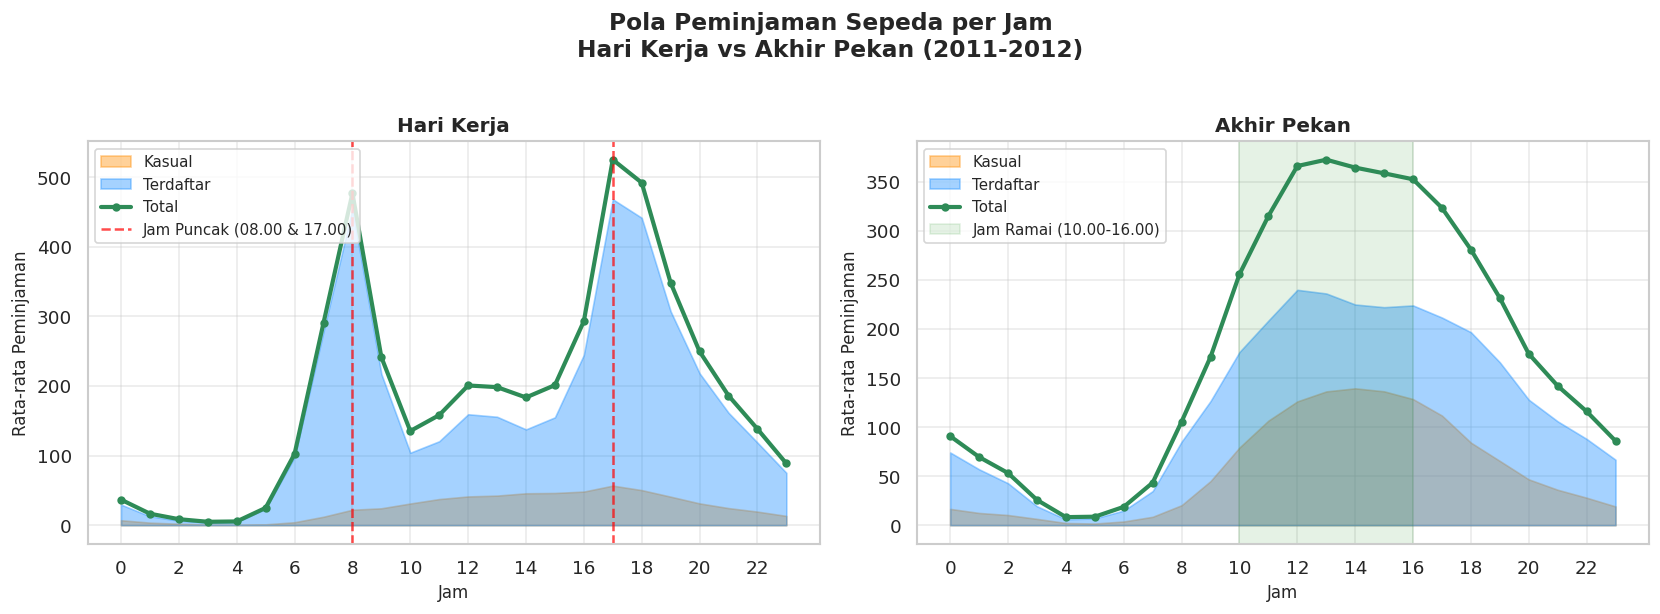

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Pola Peminjaman Sepeda per Jam\nHari Kerja vs Akhir Pekan (2011-2012)',
             fontsize=14, fontweight='bold', y=1.02)

colors = {'casual': '#FF8C00', 'registered': '#1E90FF', 'cnt': '#2E8B57'}

ax1 = axes[0]
ax1.fill_between(hourly_workday['hr'], hourly_workday['casual'],
                 alpha=0.4, color=colors['casual'], label='Kasual')
ax1.fill_between(hourly_workday['hr'], hourly_workday['registered'],
                 alpha=0.4, color=colors['registered'], label='Terdaftar')
ax1.plot(hourly_workday['hr'], hourly_workday['cnt'],
         color=colors['cnt'], linewidth=2.5, label='Total', marker='o', markersize=4)
ax1.axvline(x=8, color='red', linestyle='--', alpha=0.7, label='Jam Puncak (08.00 & 17.00)')
ax1.axvline(x=17, color='red', linestyle='--', alpha=0.7)
ax1.set_title('Hari Kerja', fontsize=12, fontweight='bold')
ax1.set_xlabel('Jam', fontsize=10)
ax1.set_ylabel('Rata-rata Peminjaman', fontsize=10)
ax1.set_xticks(range(0, 24, 2))
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.4)

ax2 = axes[1]
ax2.fill_between(hourly_weekend['hr'], hourly_weekend['casual'],
                 alpha=0.4, color=colors['casual'], label='Kasual')
ax2.fill_between(hourly_weekend['hr'], hourly_weekend['registered'],
                 alpha=0.4, color=colors['registered'], label='Terdaftar')
ax2.plot(hourly_weekend['hr'], hourly_weekend['cnt'],
         color=colors['cnt'], linewidth=2.5, label='Total', marker='o', markersize=4)
ax2.axvspan(10, 16, alpha=0.1, color='green', label='Jam Ramai (10.00-16.00)')
ax2.set_title('Akhir Pekan', fontsize=12, fontweight='bold')
ax2.set_xlabel('Jam', fontsize=10)
ax2.set_ylabel('Rata-rata Peminjaman', fontsize=10)
ax2.set_xticks(range(0, 24, 2))
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

**Insight:**
- **Hari kerja:** Terdapat 2 puncak tajam pada pukul **08.00** (berangkat kerja) dan **17.00-18.00** (pulang kerja). Pengguna terdaftar mendominasi, mengindikasikan mereka adalah komuter harian.
- **Akhir pekan:** Pola lebih landai dan merata antara pukul **10.00-16.00**, tanpa puncak tajam. Proporsi pengguna kasual lebih tinggi, mengindikasikan penggunaan untuk rekreasi.

### Pertanyaan 2: Faktor lingkungan apa yang paling memengaruhi jumlah peminjaman sepeda?

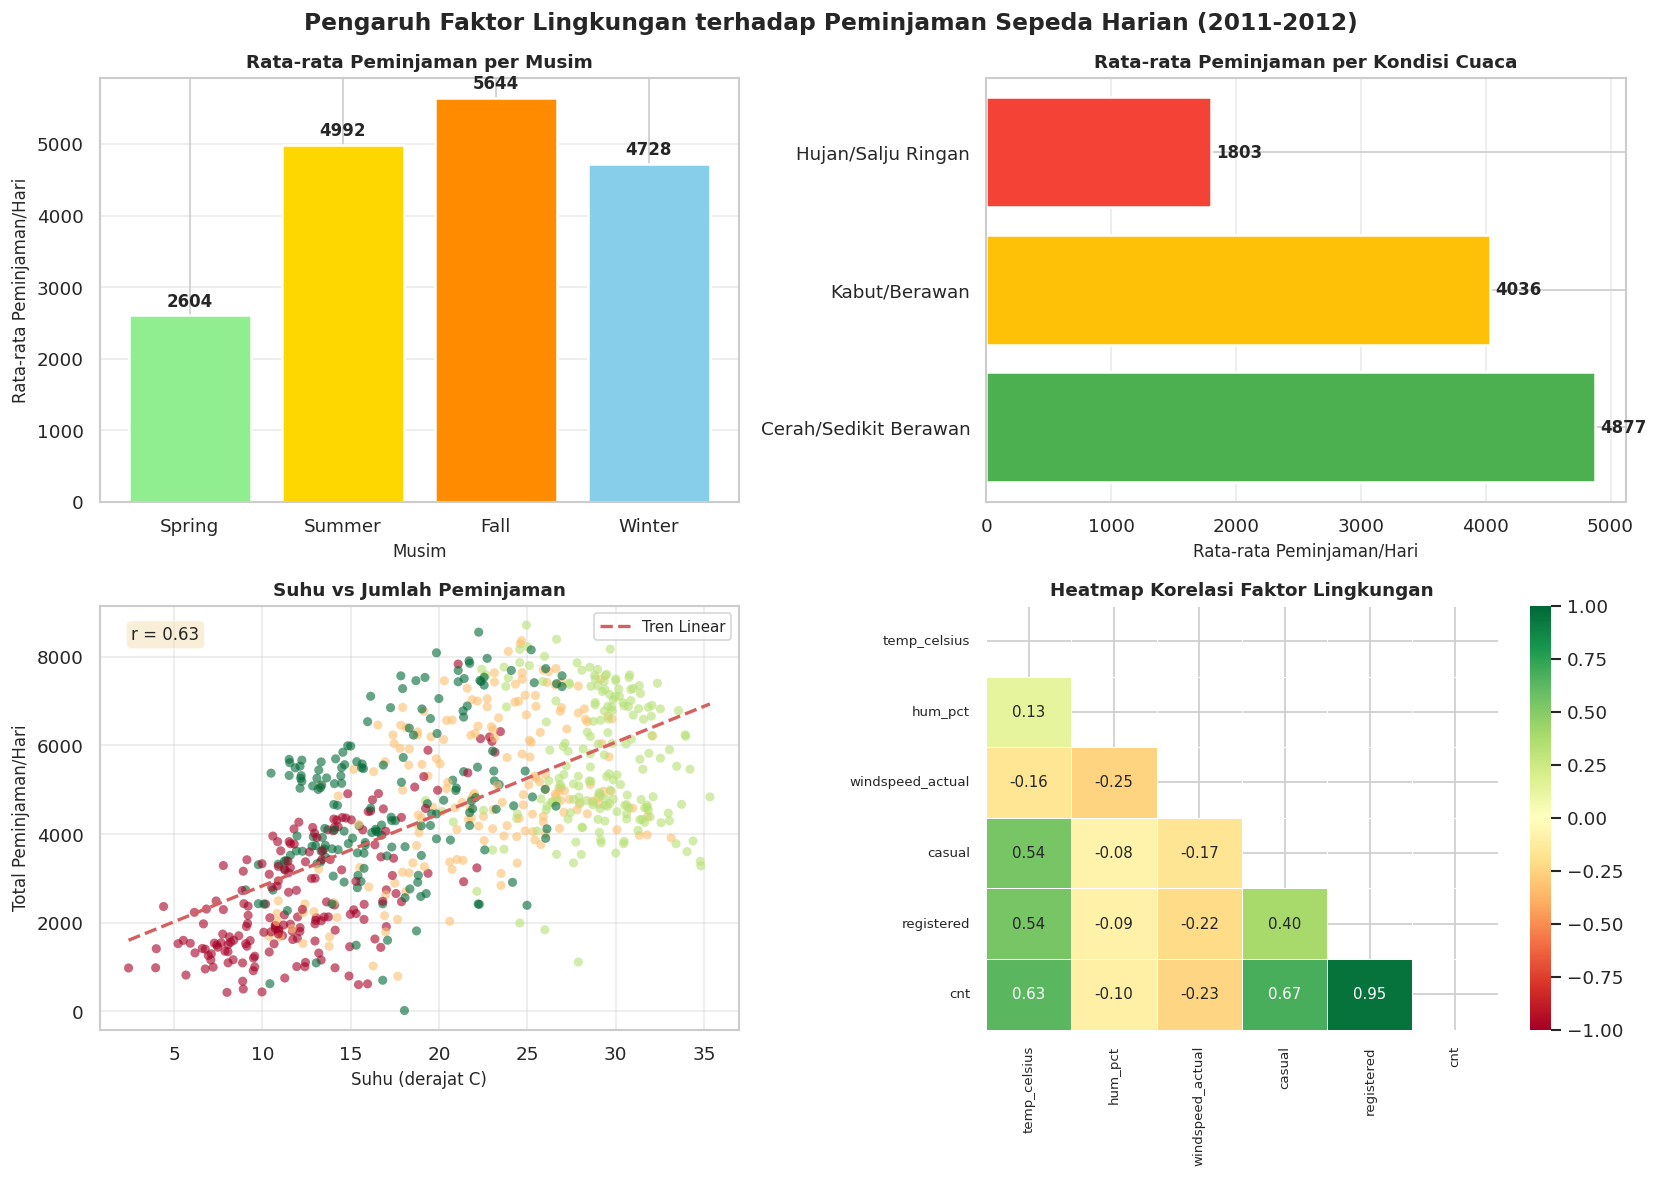

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Pengaruh Faktor Lingkungan terhadap Peminjaman Sepeda Harian (2011-2012)',
             fontsize=14, fontweight='bold')

ax1 = axes[0, 0]
season_order = ['Spring', 'Summer', 'Fall', 'Winter']
season_avg = day_df.groupby('season_label')['cnt'].mean().reindex(season_order)
bars = ax1.bar(season_avg.index, season_avg.values,
               color=['#90EE90', '#FFD700', '#FF8C00', '#87CEEB'], edgecolor='white', linewidth=1.5)
ax1.bar_label(bars, fmt='%.0f', padding=3, fontsize=10, fontweight='bold')
ax1.set_title('Rata-rata Peminjaman per Musim', fontsize=11, fontweight='bold')
ax1.set_xlabel('Musim', fontsize=10)
ax1.set_ylabel('Rata-rata Peminjaman/Hari', fontsize=10)
ax1.grid(axis='y', alpha=0.4)

ax2 = axes[0, 1]
weather_avg = day_df.groupby('weather_label')['cnt'].mean().sort_values(ascending=False)
bars2 = ax2.barh(weather_avg.index, weather_avg.values,
                 color=['#4CAF50', '#FFC107', '#F44336'][:len(weather_avg)],
                 edgecolor='white', linewidth=1.5)
ax2.bar_label(bars2, fmt='%.0f', padding=3, fontsize=10, fontweight='bold')
ax2.set_title('Rata-rata Peminjaman per Kondisi Cuaca', fontsize=11, fontweight='bold')
ax2.set_xlabel('Rata-rata Peminjaman/Hari', fontsize=10)
ax2.grid(axis='x', alpha=0.4)

ax3 = axes[1, 0]
ax3.scatter(day_df['temp_celsius'], day_df['cnt'],
            c=day_df['season'], cmap='RdYlGn', alpha=0.6, s=30, edgecolors='none')
z = np.polyfit(day_df['temp_celsius'], day_df['cnt'], 1)
p = np.poly1d(z)
x_line = np.linspace(day_df['temp_celsius'].min(), day_df['temp_celsius'].max(), 100)
ax3.plot(x_line, p(x_line), 'r--', linewidth=2, label='Tren Linear')
ax3.set_title('Suhu vs Jumlah Peminjaman', fontsize=11, fontweight='bold')
ax3.set_xlabel('Suhu (derajat C)', fontsize=10)
ax3.set_ylabel('Total Peminjaman/Hari', fontsize=10)
ax3.legend(fontsize=9)
corr_temp = day_df['temp_celsius'].corr(day_df['cnt'])
ax3.text(0.05, 0.92, f'r = {corr_temp:.2f}', transform=ax3.transAxes,
         fontsize=10, bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
ax3.grid(True, alpha=0.4)

ax4 = axes[1, 1]
corr_data = day_df[['temp_celsius', 'hum_pct', 'windspeed_actual', 'casual', 'registered', 'cnt']].corr()
mask = np.triu(np.ones_like(corr_data, dtype=bool))
sns.heatmap(corr_data, mask=mask, annot=True, fmt='.2f', cmap='RdYlGn',
            vmin=-1, vmax=1, center=0, ax=ax4,
            linewidths=0.5, annot_kws={'size': 9})
ax4.set_title('Heatmap Korelasi Faktor Lingkungan', fontsize=11, fontweight='bold')
ax4.tick_params(labelsize=8)

plt.tight_layout()
plt.show()

**Insight:**
- **Musim:** Fall (Gugur) memiliki rata-rata peminjaman tertinggi, diikuti Summer (Panas). Spring (Semi) terendah.
- **Cuaca:** Kondisi cerah/sedikit berawan menghasilkan peminjaman 2x lebih tinggi dibanding hari hujan/salju ringan.
- **Suhu:** Korelasi positif kuat (r sekitar 0.63) antara suhu dan jumlah peminjaman. Suhu optimal 15-30 derajat C.
- **Kelembapan dan Angin:** Berkorelasi negatif dengan jumlah peminjaman.

## Analisis Lanjutan (Opsional)

### Clustering Manual: Segmentasi Hari Berdasarkan Tipe Pengguna

Teknik clustering manual (binning) digunakan untuk mengelompokkan hari-hari berdasarkan rasio pengguna kasual terhadap total peminjaman, tanpa menggunakan algoritma machine learning.

In [ ]:
day_df['casual_ratio'] = day_df['casual'] / day_df['cnt']

day_df['user_segment'] = pd.cut(day_df['casual_ratio'],
                                 bins=[0, 0.15, 0.30, 1.0],
                                 labels=['Commuter Dominant', 'Mixed', 'Recreational Dominant'])

segment_stats = day_df.groupby('user_segment').agg(
    jumlah_hari=('cnt', 'count'),
    avg_casual=('casual', 'mean'),
    avg_registered=('registered', 'mean'),
    avg_total=('cnt', 'mean')
).reset_index()

print('=== Segmentasi Hari Berdasarkan Tipe Pengguna ===')
print(segment_stats.to_string(index=False))

=== Segmentasi Hari Berdasarkan Tipe Pengguna ===
         user_segment  jumlah_hari  avg_casual  avg_registered   avg_total
    Commuter Dominant          368  419.418478     3606.486413 4025.904891
                Mixed          230  923.621739     3937.678261 4861.300000
Recreational Dominant          133 1904.045113     3306.834586 5210.879699


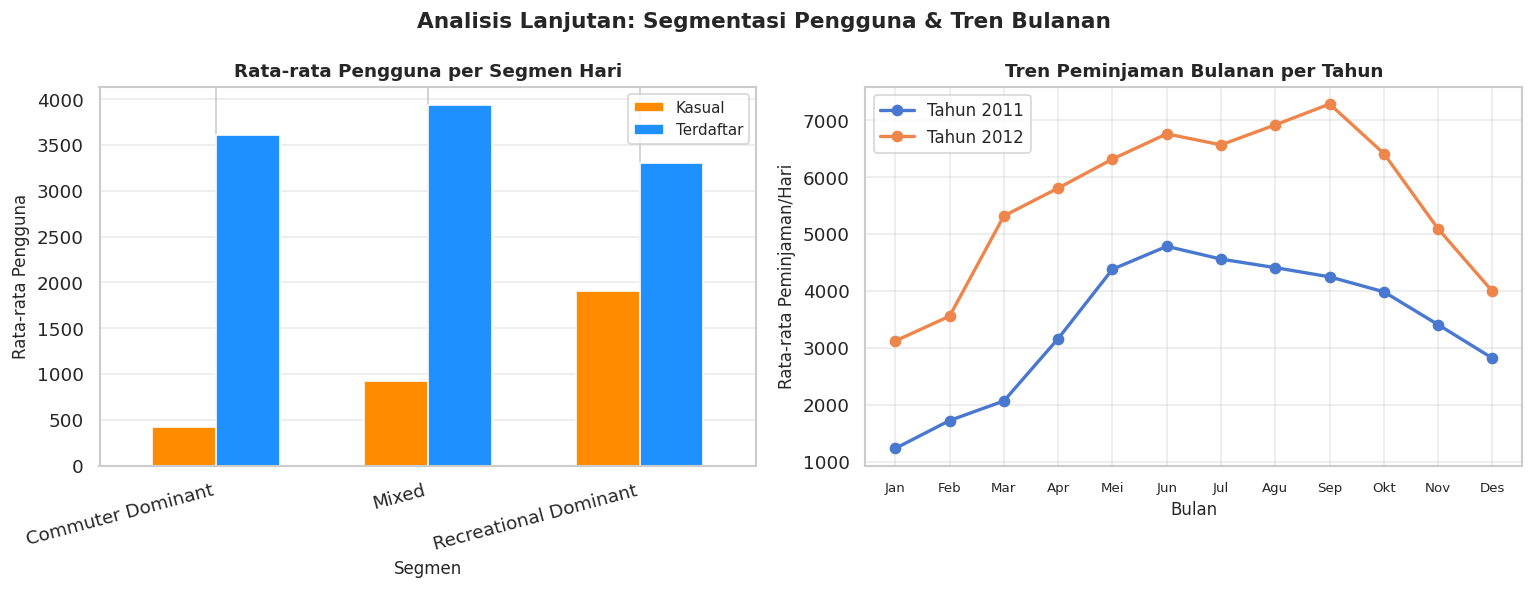

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Analisis Lanjutan: Segmentasi Pengguna & Tren Bulanan', fontsize=13, fontweight='bold')

ax1 = axes[0]
segment_stats_plot = day_df.groupby('user_segment')[['casual', 'registered']].mean()
segment_stats_plot.plot(kind='bar', ax=ax1, color=['#FF8C00', '#1E90FF'],
                        edgecolor='white', width=0.6)
ax1.set_title('Rata-rata Pengguna per Segmen Hari', fontsize=11, fontweight='bold')
ax1.set_xlabel('Segmen', fontsize=10)
ax1.set_ylabel('Rata-rata Pengguna', fontsize=10)
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=15, ha='right')
ax1.legend(['Kasual', 'Terdaftar'], fontsize=9)
ax1.grid(axis='y', alpha=0.4)

ax2 = axes[1]
monthly = day_df.groupby(['year_label', 'mnth'])['cnt'].mean().reset_index()
for yr, grp in monthly.groupby('year_label'):
    ax2.plot(grp['mnth'], grp['cnt'], marker='o', linewidth=2,
             markersize=6, label=f'Tahun {yr}')
ax2.set_title('Tren Peminjaman Bulanan per Tahun', fontsize=11, fontweight='bold')
ax2.set_xlabel('Bulan', fontsize=10)
ax2.set_ylabel('Rata-rata Peminjaman/Hari', fontsize=10)
ax2.set_xticks(range(1, 13))
ax2.set_xticklabels(['Jan','Feb','Mar','Apr','Mei','Jun','Jul','Agu','Sep','Okt','Nov','Des'],
                     fontsize=8)
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

**Insight:**
- **Commuter Dominant (rasio kasual < 15%):** Mayoritas hari kerja, volume tinggi karena pengguna terdaftar mendominasi.
- **Mixed (15-30%):** Campuran hari kerja dan akhir pekan dengan cuaca baik.
- **Recreational Dominant (> 30%):** Umumnya akhir pekan musim panas/gugur.
- Tren menunjukkan pertumbuhan konsisten dari 2011 ke 2012 sekitar 38% peningkatan.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Terdapat perbedaan signifikan pola peminjaman antara hari kerja dan akhir pekan. Pada **hari kerja**, dua puncak tajam terjadi di pukul **08.00** dan **17.00-18.00** yang didominasi pengguna terdaftar (~85%), mencerminkan pola komuting. Pada **akhir pekan**, pola lebih landai dan merata antara pukul **10.00-16.00** dengan proporsi pengguna kasual yang lebih tinggi (~30%), mencerminkan penggunaan rekreasi.

- **Conclusion pertanyaan 2:** Faktor lingkungan yang paling signifikan memengaruhi peminjaman adalah **suhu** (korelasi r sekitar 0.63), diikuti **musim** (Fall terbaik, Spring terendah), dan **kondisi cuaca** (cerah 2x lebih tinggi dari hujan). Kelembapan dan kecepatan angin berkorelasi negatif dengan peminjaman.

**Rekomendasi Action Item:**
- **Optimasi Distribusi Sepeda:** Tingkatkan ketersediaan sepeda di stasiun dekat pusat kerja/transportasi pada pukul 07.00-08.30 dan 16.30-18.30 hari kerja, serta di area rekreasi pada pukul 09.00-17.00 akhir pekan.
- **Strategi Musiman:** Tambah armada pada musim **Summer (Juni-Agustus) dan Fall (September-November)** saat permintaan tinggi. Lakukan maintenance armada pada musim **Spring (Maret-Mei)** saat permintaan rendah.
- **Peringatan Cuaca:** Implementasikan sistem notifikasi prediktif untuk pengguna terdaftar saat kondisi cuaca buruk diprediksi, disertai promosi untuk merangsang penggunaan di hari hujan ringan.
- **Program Loyalitas:** Kembangkan program loyalitas berbasis frekuensi pemakaian per bulan untuk meningkatkan retensi komuter, mengingat pengguna terdaftar menyumbang lebih dari 75% total peminjaman.